In [1]:
# ================== CELL 1 ==================
from google.colab import drive
drive.mount('/content/drive')

import os
import zipfile
from pathlib import Path

# ---- CHANGE ONLY IF YOUR ZIP IS IN DIFFERENT LOCATION ----
ZIP_PATH = "/content/drive/MyDrive/NuInsSeg.zip"
EXTRACT_PATH = "/content/NuInsSeg"

# Extract only if not already extracted
if not os.path.exists(EXTRACT_PATH):
    print("Extracting NuInsSeg.zip ...")
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_PATH)
    print("Extraction complete.")
else:
    print("Dataset already extracted.")

print("Dataset ready at:", EXTRACT_PATH)


Mounted at /content/drive
Extracting NuInsSeg.zip ...
Extraction complete.
Dataset ready at: /content/NuInsSeg


In [2]:
# ================== CELL 2 ==================
import glob, random, shutil

DATASET_ROOT = "/content/NuInsSeg"

all_images = []
all_masks = []

organ_folders = sorted(glob.glob(os.path.join(DATASET_ROOT, "human*")))

for organ in organ_folders:
    img_dir = os.path.join(organ, "tissue images")
    mask_dir = os.path.join(organ, "mask binary")

    if os.path.exists(img_dir) and os.path.exists(mask_dir):
        imgs = sorted(glob.glob(os.path.join(img_dir, "*.png")))
        masks = sorted(glob.glob(os.path.join(mask_dir, "*.png")))

        for i in range(min(len(imgs), len(masks))):
            all_images.append(imgs[i])
            all_masks.append(masks[i])

print("Total images found:", len(all_images))

pairs = list(zip(all_images, all_masks))
random.shuffle(pairs)

split = int(0.8 * len(pairs))
train_pairs = pairs[:split]
val_pairs = pairs[split:]

# Create working folders
os.makedirs("/content/train/images", exist_ok=True)
os.makedirs("/content/train/masks", exist_ok=True)
os.makedirs("/content/val/images", exist_ok=True)
os.makedirs("/content/val/masks", exist_ok=True)

# Clear old files if re-running
for f in glob.glob("/content/train/images/*"): os.remove(f)
for f in glob.glob("/content/train/masks/*"): os.remove(f)
for f in glob.glob("/content/val/images/*"): os.remove(f)
for f in glob.glob("/content/val/masks/*"): os.remove(f)

# Copy files
for img, msk in train_pairs:
    shutil.copy(img, "/content/train/images/")
    shutil.copy(msk, "/content/train/masks/")

for img, msk in val_pairs:
    shutil.copy(img, "/content/val/images/")
    shutil.copy(msk, "/content/val/masks/")

print("Train samples:", len(train_pairs))
print("Val samples:", len(val_pairs))


Total images found: 472
Train samples: 377
Val samples: 95


In [3]:
!pip install albumentations==1.4.3 tqdm --quiet


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.0/137.0 kB 10.0 MB/s eta 0:00:00


In [4]:
# ================== CELL 4 ==================
import torch
import torch.nn as nn
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from tqdm import tqdm
import glob

# ---------- Dataset ----------
class NuInsSegDataset(Dataset):
    def __init__(self, images_dir, masks_dir, transforms=None):
        self.images = sorted(glob.glob(images_dir + "/*.png"))
        self.masks  = sorted(glob.glob(masks_dir + "/*.png"))
        self.transforms = transforms

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = np.array(Image.open(self.images[idx]).convert("RGB"))
        mask = np.array(Image.open(self.masks[idx]).convert("L"))
        mask = (mask > 127).astype("float32")

        if self.transforms:
            aug = self.transforms(image=img, mask=mask)
            img, mask = aug["image"], aug["mask"]

        img = img.transpose(2,0,1) / 255.0
        mask = np.expand_dims(mask,0)

        return torch.tensor(img, dtype=torch.float32), torch.tensor(mask, dtype=torch.float32)

# ---------- Model ----------
class ConvBNRelu(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self,x): return self.block(x)

class DoubleConv(nn.Module):
    def __init__(self,in_ch,out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            ConvBNRelu(in_ch,out_ch),
            ConvBNRelu(out_ch,out_ch)
        )
    def forward(self,x): return self.conv(x)

class UNet3Plus(nn.Module):
    def __init__(self, base=32):
        super().__init__()
        nb=base
        self.enc1=DoubleConv(3,nb)
        self.pool=nn.MaxPool2d(2)
        self.enc2=DoubleConv(nb,nb*2)
        self.enc3=DoubleConv(nb*2,nb*4)
        self.enc4=DoubleConv(nb*4,nb*8)
        self.enc5=DoubleConv(nb*8,nb*16)

        self.up=nn.Upsample(scale_factor=2,mode='bilinear',align_corners=True)

        self.dec4=DoubleConv(nb*16+nb*8,nb*8)
        self.dec3=DoubleConv(nb*8+nb*4,nb*4)
        self.dec2=DoubleConv(nb*4+nb*2,nb*2)
        self.dec1=DoubleConv(nb*2+nb,nb)

        self.final=nn.Conv2d(nb,1,1)

    def forward(self,x):
        e1=self.enc1(x)
        e2=self.enc2(self.pool(e1))
        e3=self.enc3(self.pool(e2))
        e4=self.enc4(self.pool(e3))
        e5=self.enc5(self.pool(e4))

        d4=self.dec4(torch.cat([self.up(e5),e4],1))
        d3=self.dec3(torch.cat([self.up(d4),e3],1))
        d2=self.dec2(torch.cat([self.up(d3),e2],1))
        d1=self.dec1(torch.cat([self.up(d2),e1],1))

        return self.final(d1)

# ---------- Dice Loss ----------
def dice_loss(pred, target):
    pred = torch.sigmoid(pred)
    smooth = 1e-6
    inter = (pred * target).sum()
    return 1 - (2*inter + smooth)/(pred.sum()+target.sum()+smooth)

# ---------- Training ----------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_tf = A.Compose([A.Resize(256,256), A.HorizontalFlip(p=0.5)])
val_tf   = A.Compose([A.Resize(256,256)])

train_ds = NuInsSegDataset("/content/train/images","/content/train/masks",train_tf)
val_ds   = NuInsSegDataset("/content/val/images","/content/val/masks",val_tf)

train_dl = DataLoader(train_ds,batch_size=4,shuffle=True)
val_dl   = DataLoader(val_ds,batch_size=4)

model = UNet3Plus().to(device)
opt = torch.optim.Adam(model.parameters(),lr=1e-4)

best_dice=0
epochs=50

for epoch in range(epochs):
    model.train()
    train_loss=0
    for img,mask in tqdm(train_dl):
        img,mask=img.to(device),mask.to(device)
        opt.zero_grad()
        out=model(img)
        loss=dice_loss(out,mask)
        loss.backward()
        opt.step()
        train_loss+=loss.item()

    print(f"\nEpoch {epoch+1} Train Loss:",train_loss/len(train_dl))

    model.eval()
    dice_total=0
    with torch.no_grad():
        for img,mask in val_dl:
            img,mask=img.to(device),mask.to(device)
            out=model(img)
            dice=1-dice_loss(out,mask)
            dice_total+=dice.item()

    val_dice=dice_total/len(val_dl)
    print("Val Dice:",val_dice)

    if val_dice>best_dice:
        best_dice=val_dice
        torch.save(model.state_dict(),"/content/drive/MyDrive/best_unet3plus_nuinsseg.pth")
        print("Saved Best Model to Drive")

print("Training Complete")


100%|██████████| 95/95 [00:15<00:00,  6.21it/s]



Epoch 1 Train Loss: 0.5744832164362857
Val Dice: 0.4101106251279513
Saved Best Model to Drive


100%|██████████| 95/95 [00:14<00:00,  6.63it/s]



Epoch 2 Train Loss: 0.5059557092817206
Val Dice: 0.4512704685330391
Saved Best Model to Drive


100%|██████████| 95/95 [00:14<00:00,  6.72it/s]


...


Epoch 48 Train Loss: 0.12586223451714768
Val Dice: 0.8247058019042015
Saved Best Model to Drive


100%|██████████| 95/95 [00:15<00:00,  6.33it/s]



Epoch 49 Train Loss: 0.1221588555135225
Val Dice: 0.8182753572861353


100%|██████████| 95/95 [00:14<00:00,  6.50it/s]



Epoch 50 Train Loss: 0.11804941767140438
Val Dice: 0.8155165165662766
Training Complete


In [5]:
# ================== CELL 5 ==================
from google.colab import files

print("Downloading best model...")
files.download("/content/drive/MyDrive/best_unet3plus_nuinsseg.pth")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Showing 4 random validation samples...

Sample 1 → mIoU: 0.8059 | Dice: 0.8925
Sample 2 → mIoU: 0.8299 | Dice: 0.9071
Sample 3 → mIoU: 0.8421 | Dice: 0.9143
Sample 4 → mIoU: 0.7979 | Dice: 0.8876


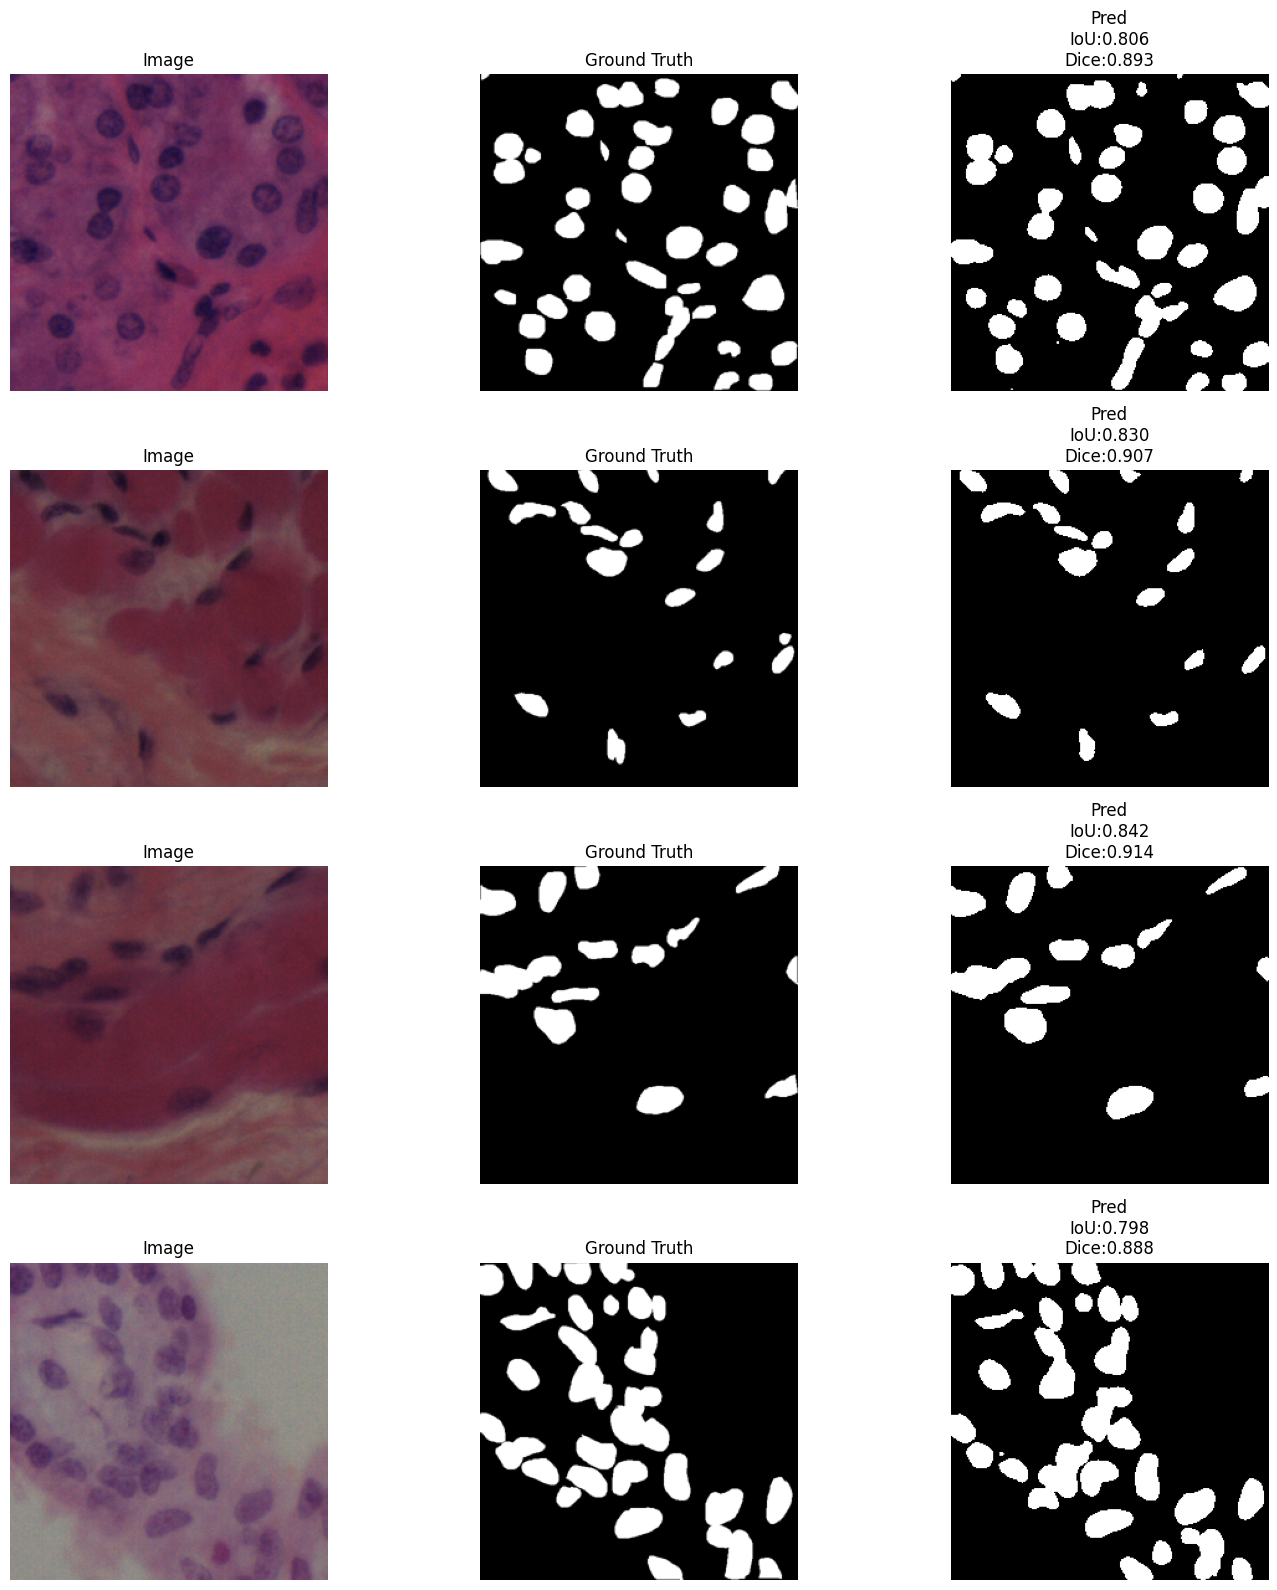

In [7]:
# ================== RANDOM VISUALIZATION CELL ==================
import torch
import torch.nn as nn
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import cv2
import glob
import random
import os
# ---------------- Select Random 4 Samples ----------------
val_images = sorted(glob.glob("/content/val/images/*.png"))
val_masks = sorted(glob.glob("/content/val/masks/*.png"))

num_samples = 4
indices = random.sample(range(len(val_images)), num_samples)

print(f"Showing {num_samples} random validation samples...\n")

# ---------------- Metric Functions ----------------
def iou(pred, gt):
    pred = pred > 0.5
    gt = gt > 0.5
    inter = np.logical_and(pred, gt).sum()
    union = np.logical_or(pred, gt).sum()
    return (inter+1e-6)/(union+1e-6)

def dice(pred, gt):
    pred = pred > 0.5
    gt = gt > 0.5
    inter = np.logical_and(pred, gt).sum()
    return (2*inter+1e-6)/(pred.sum()+gt.sum()+1e-6)

# ---------------- Run Inference & Visualize ----------------
plt.figure(figsize=(15, num_samples*4))

for i, idx in enumerate(indices):
    img_path = val_images[idx]
    gt_path = val_masks[idx]

    img = Image.open(img_path).convert("RGB").resize((256,256))
    img_np = np.array(img).astype('float32') / 255.0
    img_tensor = torch.tensor(img_np.transpose(2,0,1)).unsqueeze(0).to(device)

    with torch.no_grad():
        pred = model(img_tensor)

    mask_pred = torch.sigmoid(pred)[0,0].cpu().numpy()
    mask_bin = (mask_pred > 0.5).astype(np.uint8)

    gt = Image.open(gt_path).convert("L").resize((256,256))
    gt_np = np.array(gt).astype('float32') / 255.0

    mIoU = iou(mask_pred, gt_np)
    dice_score = dice(mask_pred, gt_np)

    print(f"Sample {i+1} → mIoU: {mIoU:.4f} | Dice: {dice_score:.4f}")

    # Plot
    plt.subplot(num_samples,3,3*i+1)
    plt.imshow(img)
    plt.title("Image")
    plt.axis("off")

    plt.subplot(num_samples,3,3*i+2)
    plt.imshow(gt_np, cmap="gray")
    plt.title("Ground Truth")
    plt.axis("off")

    plt.subplot(num_samples,3,3*i+3)
    plt.imshow(mask_bin, cmap="gray")
    plt.title(f"Pred\nIoU:{mIoU:.3f}\nDice:{dice_score:.3f}")
    plt.axis("off")

plt.tight_layout()
plt.show()
